# C2. Simulation rerun with the fixed panel

Same models and the same tuning as notebook 3, with one change: the genes come from the fixed panel of C1.
This is the design the hardware study uses, so the AUC values here are the ones to quote in the application.

Because the panel is fixed, each tumor's exact PQK features are computed once. Train/test resampling then costs
no new circuits, here or on hardware. METABRIC is the same 600 tumors in every resample.

Run time: about 10 minutes for the exact values, then 2 to 3 minutes per resample. Results are cached in
`credits/outputs/`; set `RECOMPUTE = True` to redo them.

In [1]:
SIZES       = [20, 40, 60, 80, 100, 127, 156]
REPS        = (1, 2, 3)
BANDWIDTHS  = (0.25, 0.5, 1.0)
FMAP        = "zz"
N_RESAMPLES = 10       # re-partitions of the measured TCGA tumors
N_TRAIN     = 200      # the remaining measured TCGA tumors form the held-out test set
RECOMPUTE   = False

In [2]:
import os, sys, json, time, math, warnings
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)
OUT = ROOT / "credits" / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
pd.set_option("display.width", 200)
import matplotlib.pyplot as plt

import pqk100.baselines as B
from pqk100 import report
from pqk100.backends import local_backend
from pqk100.featuremap import FEATURE_MAPS
from pqk100.kernel import features, fit_pqk
from pqk100.lattice import patch
from pqk100.lightcone import projections
from pqk100.prep import _strat_pick, to_angles
from pqk100.study import selected

project folder: D:\Active Research Projects\PQK100


## C2.1 Panel

In [3]:
z = np.load(OUT / "fixed_panel.npz", allow_pickle=True)
Zt, yt, Zm, ym = z["Z_tcga"].astype(np.float64), z["y_tcga"], z["Z_meta"].astype(np.float64), z["y_meta"]
Z_all, nt = np.vstack([Zt, Zm]), len(yt)
print(f"{nt} TCGA + {len(ym)} METABRIC tumors, {Zt.shape[1]} genes in the panel")

401 TCGA + 600 METABRIC tumors, 156 genes in the panel


## C2.2 Exact features, once per configuration

Light-cone simulation on the FakeFez lattice, as in notebook 2. Saved as float32 in `credits/outputs/exact/`.
The 1- and 2-layer files at bandwidth 0.25 are also the exact reference for the hardware runs.

In [4]:
EXACT = OUT / "exact"; EXACT.mkdir(exist_ok=True)
backend = local_backend()
patches = {n: patch(backend, n) for n in SIZES}

P = {}
t0 = time.time()
for n in SIZES:
    for r in REPS:
        for bw in BANDWIDTHS:
            f = EXACT / f"{FMAP}_n{n}_r{r}_bw{bw}.npy"
            if f.exists() and not RECOMPUTE:
                P[(n, r, bw)] = np.load(f)
                continue
            ops = FEATURE_MAPS[FMAP](n, patches[n][1], reps=r)
            P[(n, r, bw)] = projections(n, ops, to_angles(Z_all[:, :n], bw), max_cone=26)[0].astype(np.float32)
            np.save(f, P[(n, r, bw)])
    print(f"n = {n:3d} ready  ({time.time() - t0:.0f} s)")

n =  20 ready  (0 s)
n =  40 ready  (0 s)
n =  60 ready  (0 s)
n =  80 ready  (0 s)
n = 100 ready  (0 s)
n = 127 ready  (0 s)
n = 156 ready  (0 s)


## C2.3 Resamples

In [5]:
def one_resample(seed):
    rng = np.random.default_rng(seed)
    tr = _strat_pick(yt, N_TRAIN, rng)
    te = np.setdiff1d(np.arange(nt), tr)
    sets = lambda M: {"in": (M[te], yt[te]), "ext": (M[nt:], ym)}
    rows = []
    for n in SIZES:
        Z = Z_all[:, :n]
        for name, fit in (("rbf_svm", B.fit_rbf_svm), ("logreg", B.fit_logreg), ("gbm", B.fit_gbm)):
            r = B.evaluate(fit, Z[tr], yt[tr], sets(Z), seed); r.pop("params")
            rows.append(dict(seed=seed, n=n, model=name, **r))
        for reps in REPS:
            for bw in BANDWIDTHS:
                F = features(P[(n, reps, bw)])
                r = B.evaluate(fit_pqk, F[tr], yt[tr], sets(F), seed); r.pop("params")
                rows.append(dict(seed=seed, n=n, model="pqk", reps=reps, bandwidth=bw, **r))
    return rows

f = OUT / "fixed_panel_sweep.csv"
if f.exists() and not RECOMPUTE:
    sweep = pd.read_csv(f)
    print(f"read {f.name}: {sweep.seed.nunique()} resamples")
else:
    rows, t0 = [], time.time()
    for s in range(N_RESAMPLES):
        rows += one_resample(s)
        print(f"resample {s + 1}/{N_RESAMPLES} done  ({time.time() - t0:.0f} s)")
    sweep = pd.DataFrame(rows)
    sweep.to_csv(f, index=False)

read fixed_panel_sweep.csv: 10 resamples


## C2.4 Results

Mean ± standard error over resamples. PQK is the depth and bandwidth that cross-validation picks on the training set.
The standard errors understate the real uncertainty: resamples share tumors, and METABRIC is the same 600 every time.

In [6]:
NAMES = {"pqk_selected": "PQK", "rbf_svm": "RBF-SVM", "logreg": "LogReg", "gbm": "GBM"}
t = report.main_table(sweep)
fmt = lambda col, k, n: f"{t.loc[n, (col, 'mean', k)]:.3f} ± {t.loc[n, (col, 'sem', k)]:.3f}"
tab = pd.DataFrame({f"{lab} {where}": [fmt(col, k, n) for n in SIZES]
                    for col, where in (("in_auc", "TCGA"), ("ext_auc", "METABRIC")) for k, lab in NAMES.items()},
                   index=pd.Index(SIZES, name="qubits"))
tab

,PQK TCGA,RBF-SVM TCGA,LogReg TCGA,GBM TCGA,PQK METABRIC,RBF-SVM METABRIC,LogReg METABRIC,GBM METABRIC
qubits,,,,,,,,
20,0.917 ± 0.005,0.925 ± 0.005,0.924 ± 0.005,0.899 ± 0.004,0.900 ± 0.005,0.909 ± 0.003,0.908 ± 0.003,0.882 ± 0.003
40,0.929 ± 0.006,0.930 ± 0.006,0.932 ± 0.005,0.906 ± 0.005,0.910 ± 0.002,0.911 ± 0.001,0.913 ± 0.001,0.890 ± 0.003
60,0.925 ± 0.006,0.925 ± 0.006,0.932 ± 0.005,0.931 ± 0.005,0.899 ± 0.006,0.899 ± 0.006,0.901 ± 0.003,0.882 ± 0.002
80,0.924 ± 0.006,0.928 ± 0.005,0.932 ± 0.005,0.927 ± 0.005,0.900 ± 0.004,0.906 ± 0.001,0.906 ± 0.002,0.884 ± 0.003
100,0.929 ± 0.004,0.929 ± 0.005,0.934 ± 0.004,0.928 ± 0.003,0.906 ± 0.003,0.904 ± 0.003,0.904 ± 0.004,0.883 ± 0.003
127,0.930 ± 0.005,0.928 ± 0.005,0.932 ± 0.005,0.929 ± 0.003,0.899 ± 0.003,0.903 ± 0.003,0.904 ± 0.004,0.883 ± 0.003
156,0.927 ± 0.005,0.931 ± 0.004,0.934 ± 0.005,0.935 ± 0.004,0.900 ± 0.006,0.906 ± 0.003,0.908 ± 0.002,0.888 ± 0.003


In [7]:
d = report.paired_diff(sweep)
d["value"] = d["mean"].map("{:+.3f}".format) + " ± " + d.se.map("{:.3f}".format)
print("PQK minus classical, paired by resample")
d.pivot_table(index="n", columns=["vs", "metric"], values="value", aggfunc="first")

PQK minus classical, paired by resample


vs              logreg                         rbf_svm                
metric         ext_auc          in_auc         ext_auc          in_auc
n                                                                     
20      -0.008 ± 0.003  -0.007 ± 0.002  -0.009 ± 0.003  -0.007 ± 0.003
40      -0.003 ± 0.002  -0.003 ± 0.002  -0.001 ± 0.001  -0.001 ± 0.002
60      -0.002 ± 0.005  -0.007 ± 0.003  +0.000 ± 0.003  -0.000 ± 0.001
80      -0.005 ± 0.004  -0.008 ± 0.003  -0.006 ± 0.004  -0.004 ± 0.001
100     +0.002 ± 0.004  -0.005 ± 0.002  +0.002 ± 0.003  +0.000 ± 0.001
127     -0.005 ± 0.005  -0.002 ± 0.002  -0.003 ± 0.004  +0.002 ± 0.001
156     -0.008 ± 0.005  -0.006 ± 0.002  -0.006 ± 0.005  -0.004 ± 0.003

In [8]:
cnt = selected(sweep).groupby(["reps", "bandwidth"]).size().unstack(fill_value=0)
print("How often cross-validation picks each depth (rows) and bandwidth (columns):")
cnt

How often cross-validation picks each depth (rows) and bandwidth (columns):


bandwidth,0.25,0.50
reps,,
1.0,17,5
2.0,16,14
3.0,9,9


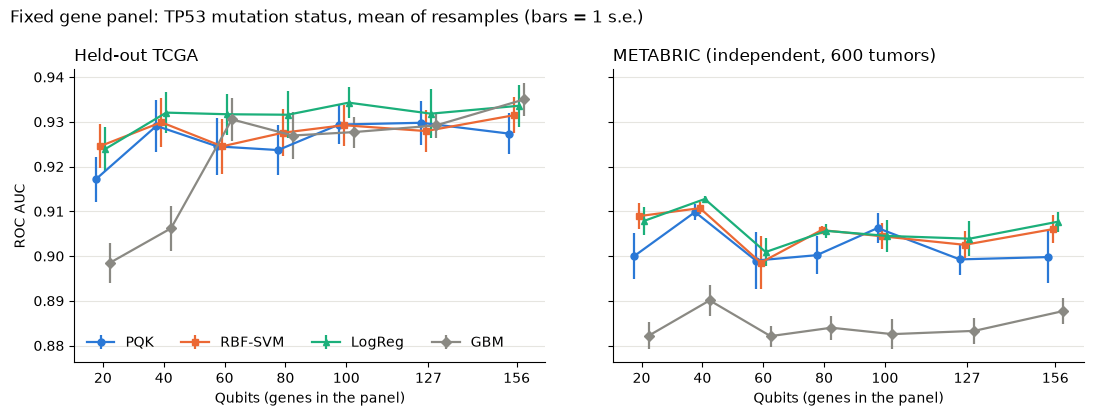

In [9]:
m = report.models_frame(sweep)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, title in zip(axes, ("in_auc", "ext_auc"), ("Held-out TCGA", "METABRIC (independent, 600 tumors)")):
    for (key, lab), dx in zip(NAMES.items(), (-2.4, -0.8, 0.8, 2.4)):
        g = m[m.model == key].groupby("n")[col]
        ax.errorbar(np.array(SIZES) + dx, g.mean().reindex(SIZES), yerr=g.apply(report.sem).reindex(SIZES),
                    color=report.COLORS[key], marker=report.MARKS[key], ms=5, lw=1.6, capsize=0, label=lab)
    ax.set_title(title, loc="left"); ax.set_xlabel("Qubits (genes in the panel)"); ax.set_xticks(SIZES)
    ax.grid(axis="y", color=report.GRID); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("ROC AUC"); axes[0].legend(frameon=False, ncols=4, loc="lower left")
fig.suptitle("Fixed gene panel: TP53 mutation status, mean of resamples (bars = 1 s.e.)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(OUT / "fixed_panel_scaling.png", dpi=160)

## C2.5 Against the per-resample design

Old values from `results/scaling.csv` (genes chosen inside each resample, 400 METABRIC tumors drawn per resample).

In [10]:
old_path = ROOT / "results" / "scaling.csv"
if old_path.exists():
    to = report.main_table(pd.read_csv(old_path))
    rows = []
    for n in SIZES:
        if n not in to.index:
            continue
        for k in ("pqk_selected", "rbf_svm", "logreg"):
            rows.append({"qubits": n, "model": NAMES[k],
                         "TCGA old": to.loc[n, ("in_auc", "mean", k)], "TCGA new": t.loc[n, ("in_auc", "mean", k)],
                         "METABRIC old": to.loc[n, ("ext_auc", "mean", k)], "METABRIC new": t.loc[n, ("ext_auc", "mean", k)]})
    cmp = pd.DataFrame(rows).round(3)
    cmp["METABRIC change"] = (cmp["METABRIC new"] - cmp["METABRIC old"]).round(3)
    display(cmp)
else:
    print("results/scaling.csv not found; skipping the comparison")

,qubits,model,TCGA old,TCGA new,METABRIC old,METABRIC new,METABRIC change
0,20,PQK,0.909,0.917,0.884,0.900,0.016
1,20,RBF-SVM,0.904,0.925,0.873,0.909,0.036
2,20,LogReg,0.911,0.924,0.880,0.908,0.028
3,40,PQK,0.907,0.929,0.881,0.910,0.029
4,40,RBF-SVM,0.915,0.930,0.888,0.911,0.023
5,40,LogReg,0.914,0.932,0.887,0.913,0.026
6,60,PQK,0.910,0.925,0.869,0.899,0.030
7,60,RBF-SVM,0.917,0.925,0.886,0.899,0.013
8,60,LogReg,0.911,0.932,0.878,0.901,0.023
9,80,PQK,0.915,0.924,0.875,0.900,0.025


## C2.6 Sampling error on METABRIC

Hanley and McNeil's formula for the standard error of one AUC, at the AUC and class balance seen here.
This backs the "about 0.016 with 600 tumors" line in the application.

In [11]:
def auc_se(a, n_pos, n_neg):
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return math.sqrt((a * (1 - a) + (n_pos - 1) * (q1 - a * a) + (n_neg - 1) * (q2 - a * a)) / (n_pos * n_neg))

a = float(t.loc[156, ("ext_auc", "mean", "pqk_selected")])
for N in (200, 400, 600):
    npos = round(N * ym.mean())
    print(f"{N} METABRIC tumors: AUC {a:.3f} has a standard error of {auc_se(a, npos, N - npos):.3f}")

200 METABRIC tumors: AUC 0.900 has a standard error of 0.026
400 METABRIC tumors: AUC 0.900 has a standard error of 0.018
600 METABRIC tumors: AUC 0.900 has a standard error of 0.015


## C2.7 Numbers for the application

In [12]:
get = lambda col, k, n=156: float(t.loc[n, (col, "mean", k)])
cl_in  = [get("in_auc", k) for k in ("rbf_svm", "logreg")]
cl_ext = [get("ext_auc", k) for k in ("rbf_svm", "logreg")]
pqk_in, pqk_ext = get("in_auc", "pqk_selected"), get("ext_auc", "pqk_selected")
dmax = d[d.n == 156]["mean"].abs().max()
npos = round(len(ym) * ym.mean())

text = f"""Fixed-panel simulation, {sweep.seed.nunique()} resamples, {time.strftime('%Y-%m-%d')}

Abstract:
In exact simulation from 20 to 156 qubits, the PQK matches tuned classical models: AUC about {pqk_in:.2f} within TCGA and {pqk_ext:.2f} on METABRIC.

Section 3, first answer:
At 156 genes, tuned RBF-SVM and logistic regression reach an AUC of {min(cl_in):.3f} to {max(cl_in):.3f} on held-out TCGA and {min(cl_ext):.3f} to {max(cl_ext):.3f} on METABRIC. Our PQK reaches {pqk_in:.3f} and {pqk_ext:.3f} in exact simulation.

Largest paired PQK-minus-classical difference at 156 qubits: {dmax:.3f} AUC.
Sampling standard error of one METABRIC AUC with {len(ym)} tumors: {auc_se(pqk_ext, npos, len(ym) - npos):.3f}.
"""
(OUT / "numbers_for_application.md").write_text(text)
print(text)

Fixed-panel simulation, 10 resamples, 2026-10-18

Abstract:
In exact simulation from 20 to 156 qubits, the PQK matches tuned classical models: AUC about 0.93 within TCGA and 0.90 on METABRIC.

Section 3, first answer:
At 156 genes, tuned RBF-SVM and logistic regression reach an AUC of 0.931 to 0.934 on held-out TCGA and 0.906 to 0.908 on METABRIC. Our PQK reaches 0.927 and 0.900 in exact simulation.

Largest paired PQK-minus-classical difference at 156 qubits: 0.008 AUC.
Sampling standard error of one METABRIC AUC with 600 tumors: 0.015.

